In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent plot style across all notebooks in this course

sns.set_theme(style='whitegrid', palette='muted') 
# adds a light grid background to all plots, making it easier to read values off the axes
# uses softer, less saturated colours which look more professional than matplotlib's default bright colours

plt.rcParams['figure.dpi'] = 110 
# increases the resolution of plots so they appear sharper, especially on high-resolution screens

print('Environment ready.')

Environment ready.


In [2]:
wine_white = pd.read_csv("datasets/winequality-white-train.csv")

## Basic Checks

In [3]:
wine_white.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.18,0.40,1.6,0.047,22.0,102.0,0.99370,3.28,0.44,10.7,5
1,6.9,0.24,0.36,20.8,0.031,40.0,139.0,0.99750,3.20,0.33,11.0,6
2,6.3,0.18,0.36,1.2,0.034,26.0,111.0,0.99074,3.16,0.51,11.0,6
3,6.2,0.21,0.38,6.8,0.036,64.0,245.0,0.99510,3.06,0.36,9.3,6
4,8.5,0.26,0.21,16.2,0.074,41.0,197.0,0.99800,3.02,0.50,9.8,3


In [4]:
# Shape
wine_white.shape

(3168, 12)

In [5]:
# Data types
wine_white.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [6]:
# Summary statistics
wine_white.describe().round(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00
mean,6.84,0.28,0.33,5.85,0.05,34.75,136.99,0.99,3.19,0.49,10.59,5.86
std,0.87,0.10,0.12,4.71,0.02,16.62,42.81,0.00,0.15,0.11,1.22,0.89
min,3.80,0.08,0.00,0.60,0.01,2.00,9.00,0.99,2.72,0.22,8.00,3.00
25%,6.30,0.21,0.27,1.60,0.04,23.00,106.00,0.99,3.09,0.41,9.50,5.00
50%,6.80,0.26,0.32,4.70,0.04,33.00,133.00,0.99,3.18,0.48,10.40,6.00
75%,7.30,0.33,0.39,8.80,0.05,45.00,166.00,1.00,3.29,0.55,11.40,6.00
max,14.20,1.00,1.66,26.05,0.29,146.50,366.50,1.00,3.82,1.08,14.05,9.00


In [7]:
# Null values
wine_white.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

0 null values

## Binarising `quality`
We binarise quality with quality >= 7 being a good wine, and quality < 7 being a bad wine

In [8]:
wine_white['quality'] = (wine_white['quality'] >= 7).astype(int)

In [9]:
wine_white.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.18,0.40,1.6,0.047,22.0,102.0,0.99370,3.28,0.44,10.7,0
1,6.9,0.24,0.36,20.8,0.031,40.0,139.0,0.99750,3.20,0.33,11.0,0
2,6.3,0.18,0.36,1.2,0.034,26.0,111.0,0.99074,3.16,0.51,11.0,0
3,6.2,0.21,0.38,6.8,0.036,64.0,245.0,0.99510,3.06,0.36,9.3,0
4,8.5,0.26,0.21,16.2,0.074,41.0,197.0,0.99800,3.02,0.50,9.8,0


In [10]:
wine_white['quality'].value_counts()

quality
0    2508
1     660
Name: count, dtype: int64

In [11]:
print("Positive class rate:", wine_white['quality'].mean().round(2))

Positive class rate: 0.21


## Univariate Distributions

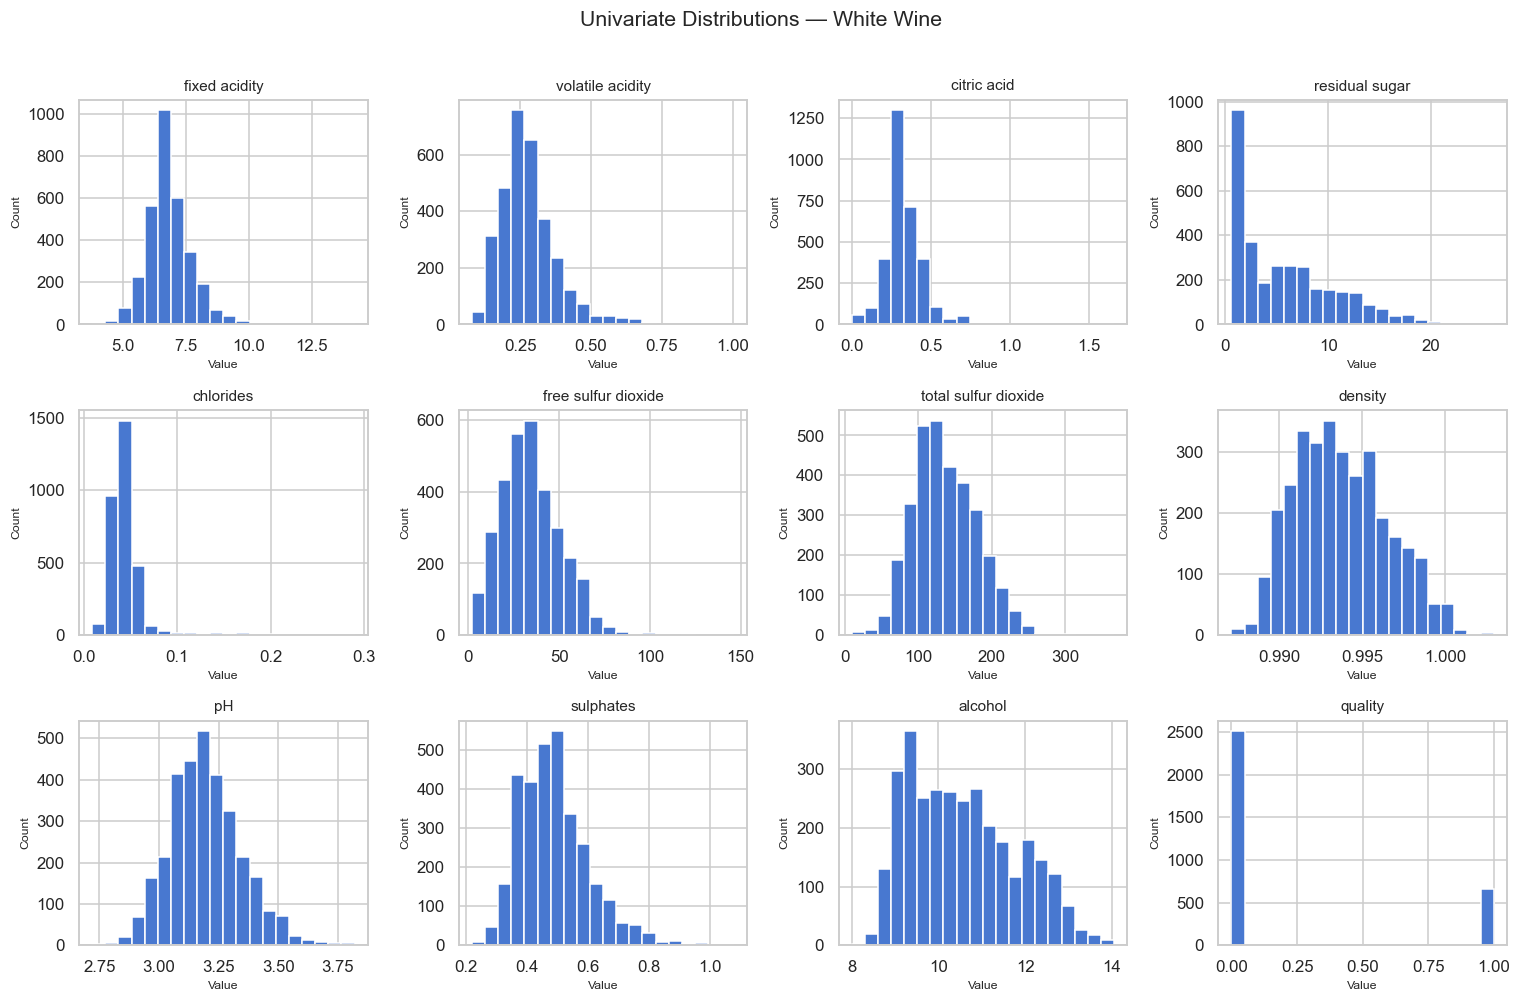

In [12]:
fig, axes = plt.subplots(3, 4, figsize=(14, 9))

# Flatten the 2D axes array (shape 3x4) into a 1D array of 12 elements
for ax, col in zip(axes.flatten(), wine_white.columns):
    ax.hist(wine_white[col], bins=20, edgecolor='white')
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('Value', fontsize=8)
    ax.set_ylabel('Count', fontsize=8)

plt.suptitle('Univariate Distributions — White Wine', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

#### Well behaved
`pH`: Unimodal and fully symmetric, forming a classic bell-shaped distribution.

`Density`: Nearly symmetric and bell-shaped, with a subtle shift toward higher values.

`Total Sulfur Dioxide`: Broad, well-behaved bell-shaped distribution.

`Fixed Acidity`: Mostly symmetric, trailing off slightly into higher values.

#### Skewed/Multimodal
`Volatile Acidity`: Right-skewed, concentrated heavily at low values with a long upper tail.

`Free Sulfur Dioxide`: Right-skewed, with most observations clustered in the lower region tapering toward higher values.

`Sulphates`: Moderately right-skewed, peaking early and trailing off gradually.

`Citric Acid`: Sharply peaked around a central concentration, with a thin upper tail.

`Residual Sugar`: Heavily right-skewed, with the vast majority concentrated at low levels and a long tail extending toward sweeter wines.

`Chlorides`: Tightly clustered near low values with a severe, sparse upper tail.

`Alcohol`: Bimodal with distinct secondary peaks

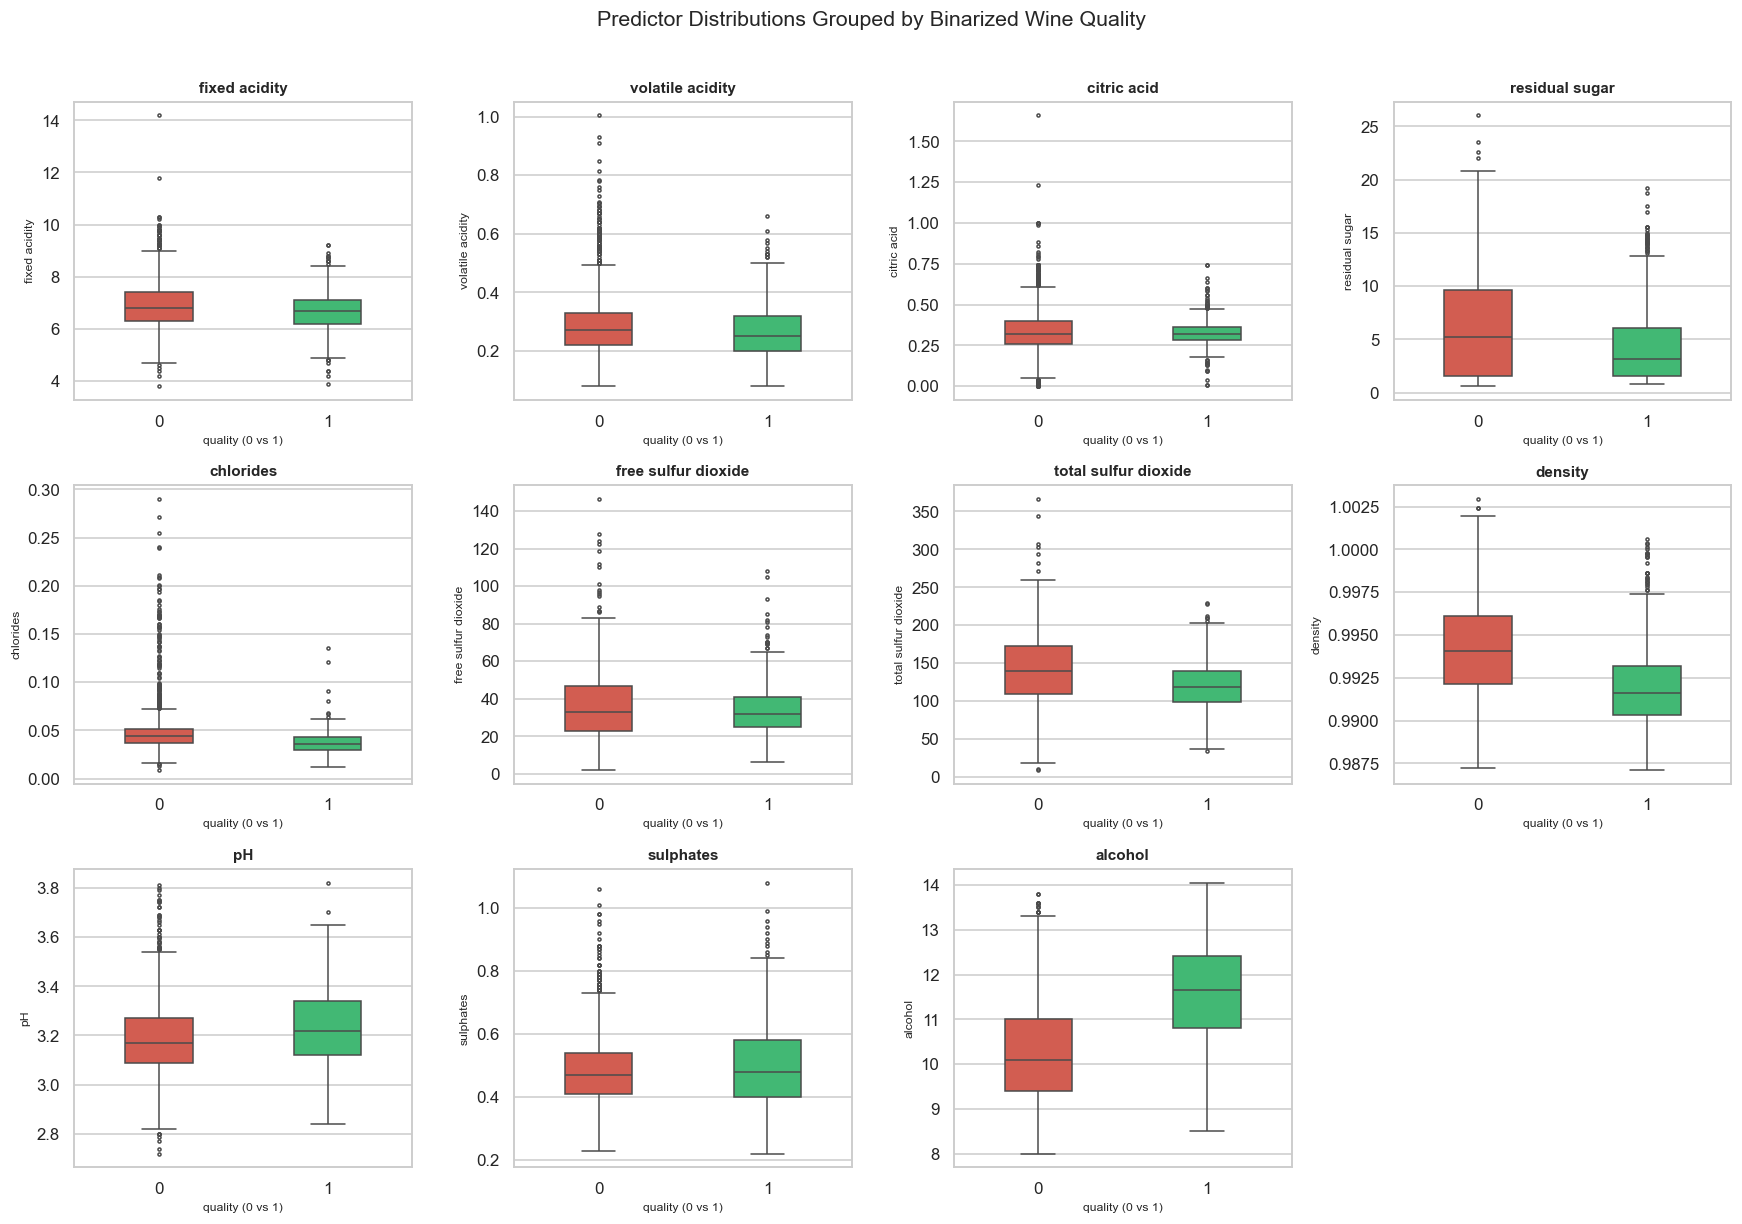

In [13]:
# Predictors excluding the binarized target 'quality'
predictors = [
    'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
    'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
    'pH', 'sulphates', 'alcohol'
]

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes_flat = axes.flatten()

for i, pred in enumerate(predictors):
    ax = axes_flat[i]
    sns.boxplot(
        data=wine_white, 
        x='quality', 
        y=pred, 
        hue='quality',    # Assign hue to match x
        legend=False,     # Suppress extra legend
        ax=ax, 
        palette=['#e74c3c', '#2ecc71'], 
        width=0.4,
        fliersize=2
    )
    ax.set_title(pred, fontsize=10, fontweight='bold')
    ax.set_xlabel('quality (0 vs 1)', fontsize=8)
    ax.set_ylabel(pred, fontsize=8)

# Remove the empty 12th panel in the 3x4 grid
fig.delaxes(axes_flat[-1])

plt.suptitle('Predictor Distributions Grouped by Binarized Wine Quality', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

Some variables that may be significant based on visual inspection of the box plots:

- `alcohol`: Positive class shows a significantly higher median and overall distribution compared to negative class, with minimal overlap in their interquartile ranges. 
- `density`: Positive class has a noticeably lower median density than negative class, displaying clear visual separation between the two distributions. 
- `residual sugar`: Negative class has a higher median and a noticeably wider distribution extending into higher concentrations compared to positive class.   
- `total sulfur dioxide`: Positive class exhibits a lower median concentration compared to negative class.   

## Correlation Matrix

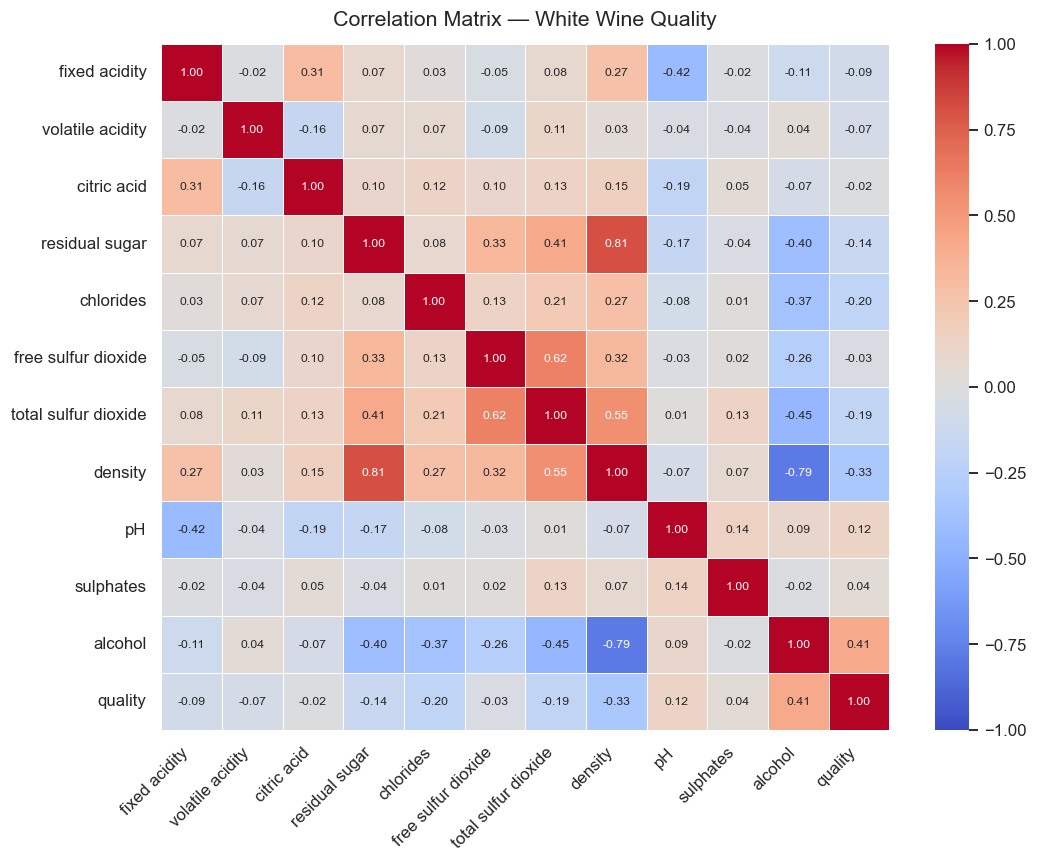

In [14]:
# Compute correlation matrix for the white wine dataset
corr = wine_white.corr()

# Increased figure size (10x8) so numbers and labels don't overlap with 12 features
fig, ax = plt.subplots(figsize=(10, 8))

# Draw the heatmap
sns.heatmap(
    corr, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm',
    vmin=-1, 
    vmax=1, 
    linewidths=0.5, 
    annot_kws={"size": 8},  # Slightly smaller text size for clarity
    ax=ax
)

# Formatting title and axis tick labels
ax.set_title('Correlation Matrix — White Wine Quality', fontsize=14, pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

- `density` $\leftrightarrow$ `residual sugar` ($r = 0.81$): This is the strongest positive correlation between any two predictors in the dataset. 
- `density` $\leftrightarrow$ `alcohol` ($r = -0.79$): This is the strongest negative correlation between any two predictors in the dataset. Higher alcohol content lowers the density of the wine.
- `alcohol` $\leftrightarrow$ `quality` ($r = 0.41$): Has the strongest direct positive correlation with quality.
- `density` $\leftrightarrow$ `quality` ($r = -0.33$): Has the strongest negative correlation with quality. However, note that density is heavily tied to alcohol ($r = -0.79$), which has the highest positive correlation with `quality`

## Candidate transformations
Naive Bayes and LDA assume Gaussian predictors within each class, so strong right skew hurts them. Rule: take the natural log of a predictor if its raw skewness is above 0.75 and the log reduces |skewness|. A log has no fitted parameters, so applying it outside the CV pipeline causes no leakage.

In [15]:
X_raw = wine_white[predictors]
skew = pd.DataFrame({
    'raw skew': X_raw.skew(),
    'log skew': np.log(X_raw.where(X_raw > 0)).skew(),
})
skew['take log'] = (skew['raw skew'] > 0.75) & (skew['log skew'].abs() < skew['raw skew'].abs())
skew.round(2)

,raw skew,log skew,take log
fixed acidity,0.71,0.09,False
volatile acidity,1.51,0.14,True
citric acid,1.36,-2.14,False
residual sugar,0.91,-0.06,True
chlorides,4.72,1.03,True
free sulfur dioxide,0.81,-0.91,False
total sulfur dioxide,0.39,-0.94,False
density,0.32,0.32,False
pH,0.45,0.29,False
sulphates,0.89,0.16,True


We log `volatile acidity`, `residual sugar`, `chlorides` and `sulphates`. `citric acid` has zeros and becomes more skewed under a log. `free sulfur dioxide` overshoots into left skew (0.81 to -0.91), so both stay on the raw scale. This list is stored once in `wine_utils.LOG_FEATURES` and used by every later notebook.

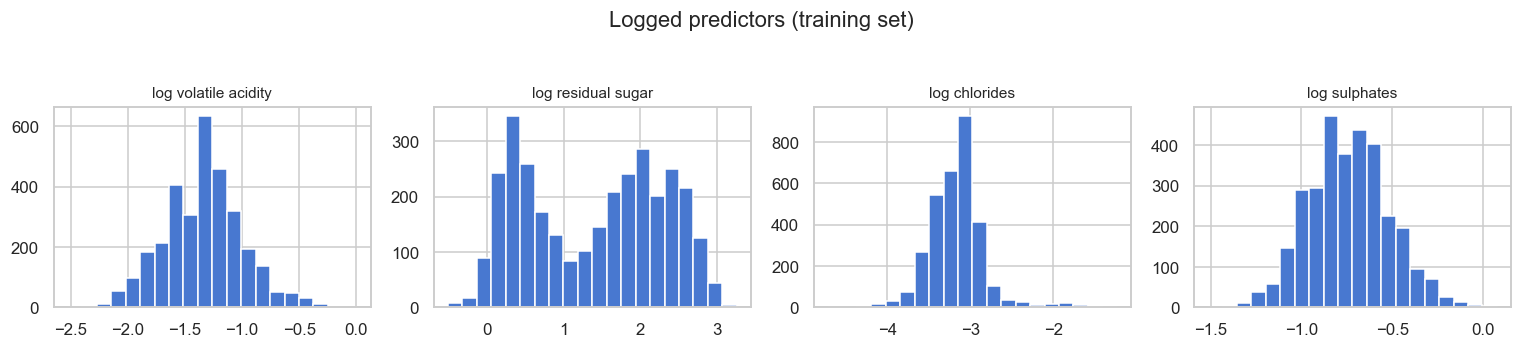

In [16]:
from wine_utils import LOG_FEATURES, transform

fig, axes = plt.subplots(1, len(LOG_FEATURES), figsize=(14, 3))
X_log = transform(X_raw)
for ax, col in zip(axes, LOG_FEATURES):
    ax.hist(X_log[f'log {col}'], bins=20, edgecolor='white')
    ax.set_title(f'log {col}', fontsize=10)
plt.suptitle('Logged predictors (training set)', y=1.05)
plt.tight_layout()
plt.show()

## Collinearity (VIF)
VIFs on the transformed predictors. Values above 10 indicate serious collinearity, which makes logistic coefficients unstable and breaks Naive Bayes' independence assumption.

In [17]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

Xc = sm.add_constant(X_log)
vif = pd.Series(
    [variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
    index=X_log.columns, name='VIF',
).sort_values(ascending=False)
vif.round(1)

density                 15.4
alcohol                  6.5
log residual sugar       5.9
total sulfur dioxide     2.3
fixed acidity            2.2
free sulfur dioxide      1.8
pH                       1.7
log chlorides            1.4
citric acid              1.2
log volatile acidity     1.2
log sulphates            1.1
Name: VIF, dtype: float64

`density` has by far the largest VIF: it is almost fully explained by residual sugar and alcohol, matching the correlations above. We keep all 11 predictors in the candidate pool rather than drop `density` by hand. The L1-penalised logistic model handles this through CV-chosen shrinkage, and the effect on Naive Bayes, which assumes independence, is discussed in the comparison.

## Class-conditional spread (LDA assumption)
LDA assumes both classes share one covariance matrix. Ratios of class standard deviations far from 1 are a warning sign.

In [18]:
y_bin = wine_white['quality']  # already binarised above
sd = X_log.groupby(y_bin).std().T
sd.columns = ['SD not good', 'SD good']
sd['ratio good / not good'] = sd['SD good'] / sd['SD not good']
sd.round(3)

,SD not good,SD good,ratio good / not good
fixed acidity,0.887,0.785,0.885
log volatile acidity,0.337,0.351,1.041
citric acid,0.131,0.082,0.627
log residual sugar,0.930,0.778,0.837
log chlorides,0.332,0.274,0.826
free sulfur dioxide,17.279,13.804,0.799
total sulfur dioxide,44.497,30.789,0.692
density,0.003,0.002,0.895
pH,0.148,0.156,1.052
log sulphates,0.214,0.258,1.205


Most ratios lie within about 0.8-1.2, but good wines are noticeably less spread on `citric acid` (0.63) and `total sulfur dioxide` (0.69). The equal-covariance assumption is therefore only approximately met even within white wine alone, which is one more reason not to pool red and white wines (whose chemistry differs far more). We keep LDA as required by the brief and interpret its results with this in mind.